<a href="https://colab.research.google.com/github/DaniloMonari/pet-feeder-detector/blob/main/Pet_feeder_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Monta o Google Drive
drive.mount('/content/drive')

# Defina o caminho exato onde está sua pasta no Drive
# Exemplo: '/content/drive/MyDrive/dataset_comedouro'
DATASET_PATH = '/content/drive/MyDrive/DIO/Desafio Rede Neural/dataset_comedouro'

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

# 2. Carrega as imagens dividindo em 80% treino e 20% validação
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# 3. Normalização rápida para a escala [-1, 1] da MobileNetV2
def normalizar(image, label):
    image = (tf.cast(image, tf.float32) / 127.5) - 1.0
    return image, label

train_data = train_ds.map(normalizar).prefetch(tf.data.AUTOTUNE)
val_data = val_ds.map(normalizar).prefetch(tf.data.AUTOTUNE)

print("Classes identificadas:", train_ds.class_names)

Mounted at /content/drive
Found 512 files belonging to 2 classes.
Using 410 files for training.
Found 512 files belonging to 2 classes.
Using 102 files for validation.
Classes identificadas: ['comedouro_cheio', 'comedouro_vazio']


In [3]:
# 1. Carrega a base convolucional pré-treinada (pesos congelados)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# 2. Monta o modelo base
model_base = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_base.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. Treinamento rápido (5 épocas)
history_base = model_base.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

loss_base, acc_base = model_base.evaluate(val_data)
print(f"\n-> Modelo Base - Acurácia: {acc_base * 100:.2f}% | Loss: {loss_base:.4f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.6976 - loss: 0.6062 - val_accuracy: 0.9314 - val_loss: 0.2658
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9683 - loss: 0.1674 - val_accuracy: 0.9902 - val_loss: 0.0902
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9927 - loss: 0.0777 - val_accuracy: 1.0000 - val_loss: 0.0511
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9976 - loss: 0.0472 - val_accuracy: 1.0000 - val_loss: 0.0338
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9976 - loss: 0.0368 - val_accuracy: 1.0000 - val_loss: 0.0264
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 1.0000 - loss: 0.0264

-> Modelo Base - Acurácia: 100.00% | Loss: 0.0264


In [4]:
# 1. Mesma base congelada
base_model_opt = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights='imagenet'
)
base_model_opt.trainable = False

# 2. Arquitetura otimizada
model_opt = tf.keras.Sequential([
    base_model_opt,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. Treina pelas mesmas 5 épocas
history_opt = model_opt.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

loss_opt, acc_opt = model_opt.evaluate(val_data)
print(f"\n-> Modelo Otimizado - Acurácia: {acc_opt * 100:.2f}% | Loss: {loss_opt:.4f}")

Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 891ms/step - accuracy: 0.9268 - loss: 0.2174 - val_accuracy: 1.0000 - val_loss: 0.0263
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9976 - loss: 0.0180 - val_accuracy: 1.0000 - val_loss: 0.0047
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9976 - loss: 0.0100 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9976 - loss: 0.0067 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 3.8809e-04
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 3.8809e-04

-> Modelo Otimizado - Acurácia: 100.00% | Loss: 0.0004


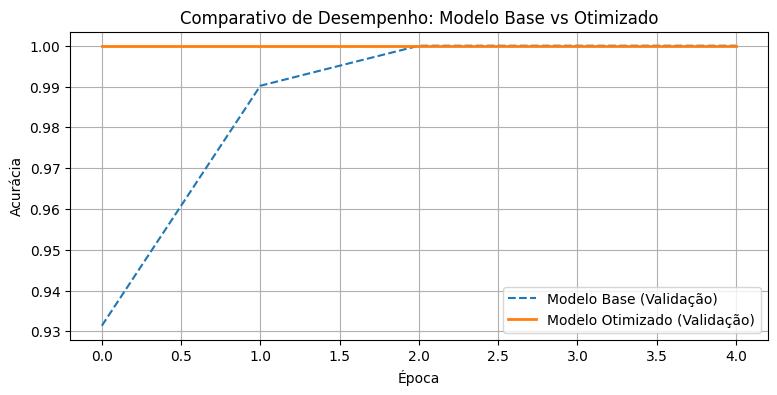


================== RESULTADO FINAL DO DESAFIO ==================
Modelo Base:      Loss = 0.0264 | Acurácia = 100.00%
Modelo Otimizado: Loss = 0.0004 | Acurácia = 100.00%


In [5]:
# Gráfico comparativo de acurácia
plt.figure(figsize=(9, 4))
plt.plot(history_base.history['val_accuracy'], label='Modelo Base (Validação)', linestyle='--')
plt.plot(history_opt.history['val_accuracy'], label='Modelo Otimizado (Validação)', linewidth=2)
plt.title('Comparativo de Desempenho: Modelo Base vs Otimizado')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)
plt.show()

print("\n================== RESULTADO FINAL DO DESAFIO ==================")
print(f"Modelo Base:      Loss = {loss_base:.4f} | Acurácia = {acc_base * 100:.2f}%")
print(f"Modelo Otimizado: Loss = {loss_opt:.4f} | Acurácia = {acc_opt * 100:.2f}%")
print("================================================================")

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


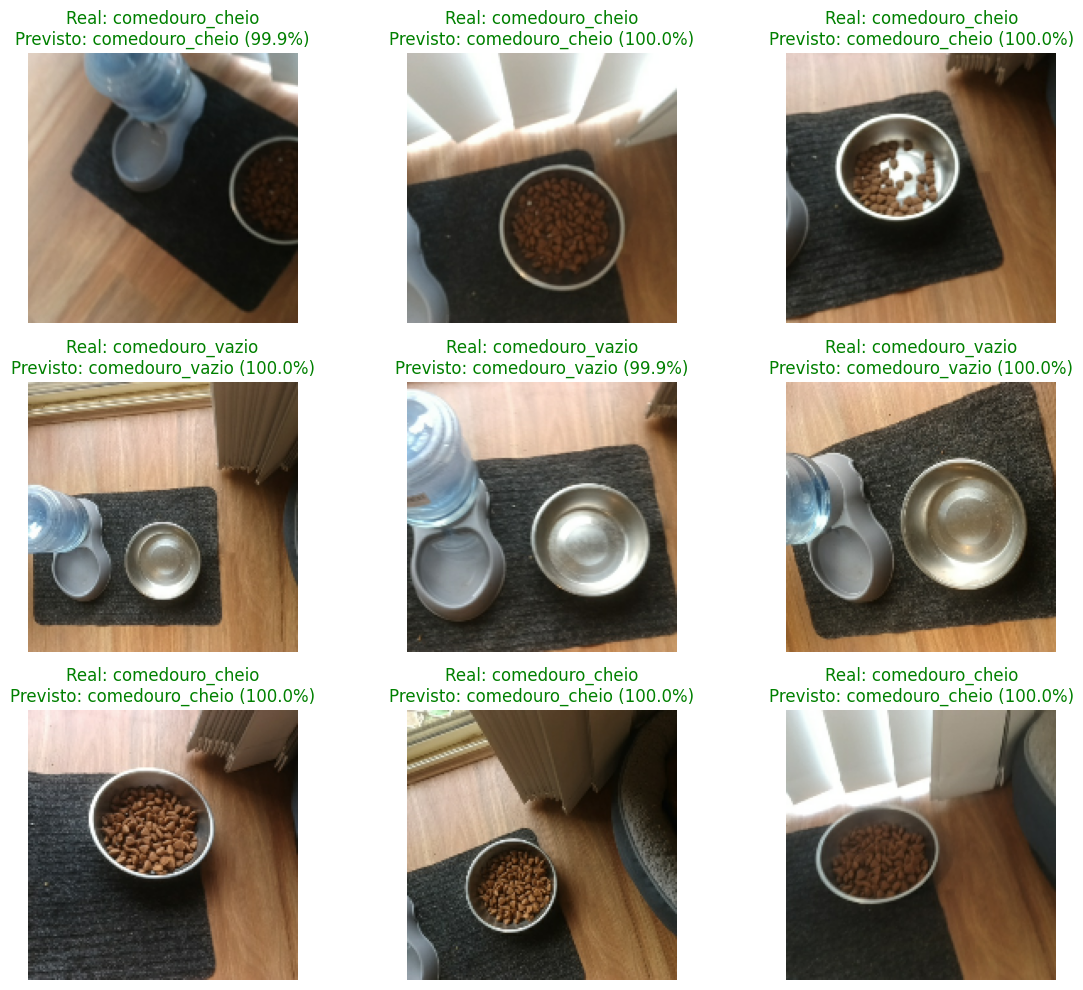

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Pega um lote de validação
for images, labels in val_data.take(1):
    preds = model_opt.predict(images)

    plt.figure(figsize=(12, 10))
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        # Desfaz a normalização para plotar a imagem original
        img_mostrar = ((images[i].numpy() + 1.0) * 127.5).astype("uint8")
        plt.imshow(img_mostrar)

        real = train_ds.class_names[int(labels[i])]
        previsto_idx = 1 if preds[i][0] > 0.5 else 0
        previsto = train_ds.class_names[previsto_idx]
        confianca = preds[i][0] if previsto_idx == 1 else (1 - preds[i][0])

        cor = "green" if real == previsto else "red"
        plt.title(f"Real: {real}\nPrevisto: {previsto} ({confianca*100:.1f}%)", color=cor)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Selecione uma foto da vasilha para testar:


Saving images.jfif to images.jfif
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


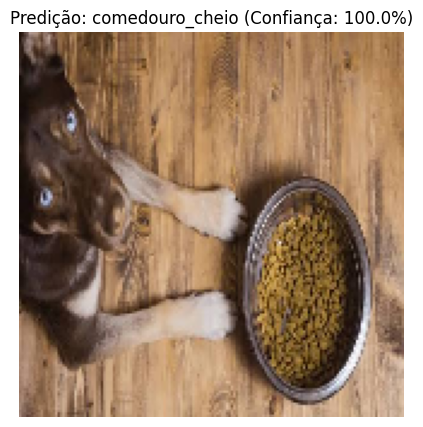

In [10]:
import numpy as np
from google.colab import files
from tensorflow.keras.preprocessing import image

print("Selecione uma foto da vasilha para testar:")
uploaded = files.upload()
nome_imagem = list(uploaded.keys())[0]

# Carrega e redimensiona a imagem para a entrada do modelo
img = image.load_img(nome_imagem, target_size=(160, 160))
img_array = image.img_to_array(img)
img_array = (img_array / 127.5) - 1.0  # Normalização [-1, 1]
img_batch = np.expand_dims(img_array, axis=0)

# Predição no modelo otimizado (ou use model_base se preferir)
pred = model_opt.predict(img_batch)[0][0]

# Mapeamento do resultado
# train_ds.class_names geralmente ordena em ['vasilha_cheia', 'vasilha_vazia']
if pred > 0.5:
    resultado = f"{train_ds.class_names[1]} (Confiança: {pred * 100:.1f}%)"
else:
    resultado = f"{train_ds.class_names[0]} (Confiança: {(1 - pred) * 100:.1f}%)"

# Exibe a foto com o resultado
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Predição: {resultado}")
plt.axis("off")
plt.show()